# Implementation from Scratch: A Convolutional Neural Network in Pure NumPy
## Execution guide, correctness tests, complexity analysis and limitations

*COMP6001 - Computer Vision and Multimodal Machine Learning - Final Project*

## Section 1 - Objective of this Notebook

The other notebooks use PyTorch and scikit-learn, which hide how the algorithms work. This notebook **implements the main algorithm of the project, a convolutional neural network, from scratch** using only NumPy: the convolution, ReLU, max-pooling and fully connected layers, the softmax cross-entropy loss, backpropagation through every layer, and the Adam optimiser. No deep-learning library is used to build or train the network.

The notebook then does five things around that implementation:

1. gives a complete **guide to executing the whole project** (Section 2);
2. **proves the implementation is correct** with a numerical gradient check and by matching PyTorch's outputs, gradients and training trajectory (Section 7);
3. **trains it on the plant-disease images** and evaluates it on the same test images as every other model (Sections 8 - 10);
4. analyses the **computational and memory complexity** theoretically and by measurement (Section 11);
5. analyses the **limitations and possible bugs** of the code, with automated edge-case tests (Section 12).

## Section 2 - How to Execute the Project

**Requirements.** Python 3.10 or newer, `git` (to download the data), and the packages in `requirements.txt`. On macOS use `python3` and `pip3`.

```
python3 -m venv venv
source venv/bin/activate            # Windows: venv\Scripts\activate
pip install -r requirements.txt
```

**Folder layout.** Notebooks live in `notebooks/`; they create `data/` (images, split file, cached features), `models/` (trained weights), and `results/` (figures, tables, predictions) next to it.

**Run order.** Open each notebook in VS Code or Jupyter, select the Python kernel and choose *Run All*.

| Order | Notebook | What it does | Needs | Approx. run time |
|---|---|---|---|---|
| 1 | `dataset_analysis.ipynb` | Downloads the data, builds the multi-modal table and the train/val/test split, analyses the dataset | internet, git | 5 - 10 min |
| 2 | `custom_cnn.ipynb` | Custom CNN in PyTorch: preprocessing, features, training, evaluation | notebook 1 | 20 - 40 min |
| 3 | `benchmark_methods.ipynb` | Seven benchmark methods (SVM, random forest, ResNet18, multi-modal) | notebook 1 (2 optional) | 30 - 45 min |
| 4 | `implementation_from_scratch.ipynb` (this one) | NumPy CNN, tests, complexity and limitations | notebook 1 | 5 - 10 min |
| - | `literature_review.ipynb` | Literature review (no computation) | nothing | seconds |

Each long notebook has a `QUICK_TEST = True` switch that uses a smaller dataset subset; use it first to check that your installation works, then set it to `False`. The from-scratch notebook trains for 10 epochs in both modes. Restart the kernel and run all cells after changing configuration.

The cell below prints the versions of the main libraries, which is useful for reproducing the results and for reporting bugs.

In [42]:
import platform, sys
import numpy as np, pandas as pd, scipy, sklearn, matplotlib, PIL
import torch, torchvision

print("Python      :", sys.version.split()[0], "on", platform.platform())
for name, mod in [("numpy", np), ("pandas", pd), ("scipy", scipy), ("scikit-learn", sklearn), ("matplotlib", matplotlib),
                  ("pillow", PIL), ("torch", torch), ("torchvision", torchvision)]:
    print(f"{name:12s}:", mod.__version__)
print("CPU threads :", torch.get_num_threads())

Python      : 3.11.4 on macOS-26.4.1-arm64-arm-64bit
numpy       : 1.26.4
pandas      : 3.0.5
scipy       : 1.11.4
scikit-learn: 1.9.0
matplotlib  : 3.9.2
pillow      : 10.2.0
torch       : 2.14.0
torchvision : 0.29.0
CPU threads : 4


## Section 3 - What Is Implemented from Scratch

**Algorithm.** A convolutional neural network (CNN) for image classification, the main method of the project. Everything is written with NumPy arrays:

| Component | Implemented here | Idea |
|---|---|---|
| Convolution | `Conv2D` with `im2col` / `col2im` | turn convolution into one matrix multiplication |
| Non-linearity | `ReLU` | $\max(0,x)$ |
| Down-sampling | `MaxPool2D` (2 x 2, stride 2) | keep the largest value in each window |
| Classifier | `Dense` (fully connected) and `Flatten` | $xW+b$ |
| Loss | `softmax_cross_entropy` | probabilities and their log-loss, with the gradient |
| Training | `backward()` of every layer, `Adam` | backpropagation and adaptive gradient descent |
| Initialisation | He initialisation | $W\sim\mathcal{N}(0,2/\text{fan-in})$ (He et al., 2015) |

**Network used for the experiments.** To keep a pure-NumPy network fast on a laptop, images are reduced to $32\times32$ pixels:

`Input 3x32x32 -> Conv 3x3 (8) -> ReLU -> MaxPool -> Conv 3x3 (16) -> ReLU -> MaxPool -> Flatten (1024) -> Dense 64 -> ReLU -> Dense K`

It has the same structure as the custom CNN of the main notebook (convolution blocks followed by a small classifier) but fewer and smaller layers (about 70,000 parameters), so its accuracy is not directly comparable with the $256\times256$ PyTorch model; it is evaluated on the **same test images**.

## Section 4 - Theory: Forward and Backward Pass of Every Layer

Training a network needs the gradient of the loss $\mathcal{L}$ with respect to every weight. Backpropagation computes it with the chain rule, layer by layer from the output to the input: each layer receives $\partial\mathcal{L}/\partial(\text{its output})$ and returns $\partial\mathcal{L}/\partial(\text{its input})$, and also the gradients of its own weights.

**Softmax cross-entropy.** For logits $z\in\mathbb{R}^{N\times K}$ (one row per image) and true classes $y_i$, with $p_{ic}=e^{z_{ic}}/\sum_j e^{z_{ij}}$,

$$
\mathcal{L}=\frac1N\sum_{i}\Big(\log\sum_{j}e^{z_{ij}}-z_{i,y_i}\Big),\qquad
\frac{\partial\mathcal{L}}{\partial z_{ic}}=\frac{p_{ic}-\mathbb{1}[c=y_i]}{N}.
$$

To avoid overflow the maximum of each row is subtracted from the logits before exponentiating (the result is unchanged).

**Dense layer.** $Y=XW+b$ with $X\in\mathbb{R}^{N\times n_{in}}$. Given $dY=\partial\mathcal{L}/\partial Y$,

$$
dW=X^{\top}dY,\qquad db=\sum_i dY_{i},\qquad dX=dY\,W^{\top}.
$$

**ReLU.** $Y=\max(0,X)$, so $dX=dY\odot\mathbb{1}[X>0]$.

**Max-pooling (2 x 2).** The forward pass keeps the maximum of each window and remembers *which* position it came from; the backward pass sends the gradient $dY$ only to that position and zero to the other three.

**Convolution via im2col.** A direct convolution needs four nested loops. The *im2col* trick (Chellapilla et al., 2006) copies every $k\times k\times C_{in}$ patch of the input into one row of a matrix $X_{col}\in\mathbb{R}^{(N H_{out}W_{out})\times(C_{in}k^2)}$, so that the convolution becomes one matrix product with the filters $W_{mat}\in\mathbb{R}^{C_{in}k^2\times C_{out}}$:

$$
Y_{col}=X_{col}\,W_{mat}+b,\qquad
dW_{mat}=X_{col}^{\top}\,dY_{col},\qquad db=\sum dY_{col},\qquad dX_{col}=dY_{col}\,W_{mat}^{\top}.
$$

The gradient with respect to the image is obtained by adding every row of $dX_{col}$ back to the pixels it was copied from (*col2im*); pixels that appear in several patches receive the sum of their gradients. With padding $P$ and stride 1 the output size is $H_{out}=H+2P-k+1$.

**Adam optimiser.** With gradient $g_t$ at step $t$, learning rate $\eta$, $\beta_1=0.9$, $\beta_2=0.999$, $\epsilon=10^{-8}$:

$$
m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\quad v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^{2},\quad
\theta_t=\theta_{t-1}-\eta\,\frac{m_t/(1-\beta_1^{t})}{\sqrt{v_t/(1-\beta_2^{t})}+\epsilon}.
$$

## Section 5 - Setup

Imports and settings. `QUICK_TEST = True` uses a small subset and 10 epochs. The full run also trains for 10 epochs, using up to 200 training images per class. Early stopping is configured not to interrupt these 10 epochs. After changing settings, restart the kernel and run all cells so the training cell uses the current configuration. All random numbers come from seeded generators, so the results are reproducible.

In [43]:
import warnings
warnings.filterwarnings("ignore")

import json
import time
import tracemalloc
from pathlib import Path
from numpy.lib.stride_tricks import sliding_window_view

import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix

import torch.nn as nn
import torch.nn.functional as F

QUICK_TEST = False
IMG = 32                       # images are reduced to IMG x IMG pixels
N_PER_CLASS = 40 if QUICK_TEST else 200      # training images per class
EPOCHS = 10
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
PATIENCE = EPOCHS              # do not stop before the configured 10 epochs
SEED = 42

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, MODELS = ROOT_DIR / "data", ROOT_DIR / "models"
RESULTS = ROOT_DIR / "results" / "implementation"
PRED_DIR = ROOT_DIR / "results" / "predictions"
for d in (MODELS, RESULTS, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

def save_show(name):
    plt.tight_layout()
    plt.savefig(RESULTS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Section 6 - The Implementation

### 6.1 im2col and col2im

`im2col` pads the images and uses NumPy's `sliding_window_view` to see every $k\times k$ patch without copying, then rearranges them into the matrix $X_{col}$ (one row per output position, columns ordered channel, row, column). `col2im` is its adjoint: it loops over the $k^2$ kernel offsets and adds the corresponding columns of $dX_{col}$ back into a padded image.

The memory cost of this speed-up is visible here: $X_{col}$ is about $k^2=9$ times larger than the input (analysed in Section 11).

In [44]:
def conv_out_size(size, k, pad):
    return size + 2 * pad - k + 1

def im2col(x, k, pad):
    """(N, C, H, W) -> matrix of shape (N*Ho*Wo, C*k*k); stride 1."""
    N, C, H, W = x.shape
    xp = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)))
    Ho, Wo = conv_out_size(H, k, pad), conv_out_size(W, k, pad)
    win = sliding_window_view(xp, (k, k), axis=(2, 3))                 # (N, C, Ho, Wo, k, k) - a view, no copy
    cols = win.transpose(0, 2, 3, 1, 4, 5).reshape(N * Ho * Wo, C * k * k)
    return np.ascontiguousarray(cols), Ho, Wo

def col2im(dcols, x_shape, k, pad):
    """Adjoint of im2col: add every column back to the pixels it was copied from."""
    N, C, H, W = x_shape
    Ho, Wo = conv_out_size(H, k, pad), conv_out_size(W, k, pad)
    d = dcols.reshape(N, Ho, Wo, C, k, k).transpose(0, 3, 4, 5, 1, 2)   # (N, C, k, k, Ho, Wo)
    dxp = np.zeros((N, C, H + 2 * pad, W + 2 * pad), dtype=dcols.dtype)
    for i in range(k):
        for j in range(k):
            dxp[:, :, i:i + Ho, j:j + Wo] += d[:, :, i, j]
    return dxp[:, :, pad:pad + H, pad:pad + W] if pad else dxp

### 6.2 Layers

Every layer has a `forward` method that stores what it needs for the backward pass, and a `backward` method that receives the gradient of the loss with respect to its output and returns the gradient with respect to its input. Layers with weights keep them in `params` and their gradients in `grads`.

* **Conv2D** - He-initialised filters; forward is the matrix product $X_{col}W_{mat}+b$, backward uses the three formulas of Section 4.
* **ReLU** - stores the sign mask of the input.
* **MaxPool2D** - reshapes each $2\times2$ window into 4 values, takes the arg-max (first maximum in row order, the same convention as PyTorch) and stores the index. It requires an even height and width and raises an error otherwise.
* **Flatten** and **Dense** - reshape to a matrix and multiply by the weight matrix.

In [45]:
class Conv2D:
    def __init__(self, c_in, c_out, k=3, pad=1, rng=None, dtype=np.float32):
        std = np.sqrt(2.0 / (c_in * k * k))                                  # He initialisation
        self.params = {"W": (rng.standard_normal((c_out, c_in, k, k)) * std).astype(dtype),
                       "b": np.zeros(c_out, dtype=dtype)}
        self.grads = {}
        self.k, self.pad = k, pad

    def forward(self, x, train=True):
        cols, Ho, Wo = im2col(x, self.k, self.pad)
        W = self.params["W"]
        out = cols @ W.reshape(W.shape[0], -1).T + self.params["b"]
        self.cache = (cols, x.shape)
        return np.ascontiguousarray(out.reshape(x.shape[0], Ho, Wo, -1).transpose(0, 3, 1, 2))

    def backward(self, dout):
        cols, x_shape = self.cache
        W = self.params["W"]
        d2 = dout.transpose(0, 2, 3, 1).reshape(-1, W.shape[0])             # dY_col
        self.grads["W"] = (cols.T @ d2).T.reshape(W.shape)                  # dW
        self.grads["b"] = d2.sum(axis=0)                                    # db
        return col2im(d2 @ W.reshape(W.shape[0], -1), x_shape, self.k, self.pad)   # dX


class ReLU:
    params, grads = {}, {}
    def forward(self, x, train=True):
        self.mask = x > 0
        return x * self.mask
    def backward(self, dout):
        return dout * self.mask


class MaxPool2D:
    params, grads = {}, {}
    def forward(self, x, train=True):
        N, C, H, W = x.shape
        if H % 2 or W % 2:
            raise ValueError(f"MaxPool2D needs even height and width, got {H}x{W}")
        xr = x.reshape(N, C, H // 2, 2, W // 2, 2).transpose(0, 1, 2, 4, 3, 5).reshape(N, C, H // 2, W // 2, 4)
        self.idx = xr.argmax(axis=-1)
        self.shape = x.shape
        return np.take_along_axis(xr, self.idx[..., None], axis=-1)[..., 0]
    def backward(self, dout):
        N, C, H, W = self.shape
        dxr = np.zeros((N, C, H // 2, W // 2, 4), dtype=dout.dtype)
        np.put_along_axis(dxr, self.idx[..., None], dout[..., None], axis=-1)
        return dxr.reshape(N, C, H // 2, W // 2, 2, 2).transpose(0, 1, 2, 4, 3, 5).reshape(N, C, H, W)


class Flatten:
    params, grads = {}, {}
    def forward(self, x, train=True):
        self.shape = x.shape
        return x.reshape(x.shape[0], -1)
    def backward(self, dout):
        return dout.reshape(self.shape)


class Dense:
    def __init__(self, n_in, n_out, rng=None, dtype=np.float32):
        std = np.sqrt(2.0 / n_in)
        self.params = {"W": (rng.standard_normal((n_in, n_out)) * std).astype(dtype), "b": np.zeros(n_out, dtype=dtype)}
        self.grads = {}
    def forward(self, x, train=True):
        self.x = x
        return x @ self.params["W"] + self.params["b"]
    def backward(self, dout):
        self.grads["W"] = self.x.T @ dout
        self.grads["b"] = dout.sum(axis=0)
        return dout @ self.params["W"].T

### 6.3 Loss function, network container and Adam

* `softmax_cross_entropy` returns the mean loss, the gradient $(p-\mathbb{1})/N$ with respect to the logits, and the class probabilities. It checks that the labels are valid class indices.
* `CNN` stacks the layers, runs `forward`, and runs `backward` through the layers in reverse order. `build_cnn` creates the architecture of Section 3 for any image size divisible by 4 and any number of classes.
* `Adam` keeps the two moving averages of every weight and applies the update of Section 4. It works in place on the layers' parameters.

In [46]:
def softmax_cross_entropy(logits, y):
    N, K = logits.shape
    if y.min() < 0 or y.max() >= K:
        raise IndexError(f"labels must be in [0, {K - 1}]")
    z = logits - logits.max(axis=1, keepdims=True)                          # numerical stability
    e = np.exp(z)
    s = e.sum(axis=1, keepdims=True)
    p = e / s
    loss = float((np.log(s[:, 0]) - z[np.arange(N), y]).mean())
    d = p.copy()
    d[np.arange(N), y] -= 1
    return loss, d / N, p


class CNN:
    def __init__(self, layers):
        self.layers = layers
    def forward(self, x, train=True):
        for layer in self.layers:
            x = layer.forward(x, train)
        return x
    def backward(self, dlogits):
        for layer in reversed(self.layers):
            dlogits = layer.backward(dlogits)
    def parameters(self):
        return [(layer, name) for layer in self.layers for name in layer.params]
    def n_params(self):
        return sum(layer.params[n].size for layer, n in self.parameters())
    def get_weights(self):
        return [layer.params[n].copy() for layer, n in self.parameters()]
    def set_weights(self, ws):
        for (layer, n), w in zip(self.parameters(), ws):
            layer.params[n] = w.copy()


def build_cnn(num_classes, hw=IMG, c1=8, c2=16, hidden=64, seed=SEED, dtype=np.float32):
    rng = np.random.default_rng(seed)
    flat = c2 * (hw // 4) ** 2
    return CNN([Conv2D(3, c1, rng=rng, dtype=dtype), ReLU(), MaxPool2D(),
                Conv2D(c1, c2, rng=rng, dtype=dtype), ReLU(), MaxPool2D(),
                Flatten(), Dense(flat, hidden, rng=rng, dtype=dtype), ReLU(), Dense(hidden, num_classes, rng=rng, dtype=dtype)])


class Adam:
    def __init__(self, model, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.model, self.lr, self.b1, self.b2, self.eps, self.t = model, lr, beta1, beta2, eps, 0
        self.m = [np.zeros_like(l.params[n]) for l, n in model.parameters()]
        self.v = [np.zeros_like(l.params[n]) for l, n in model.parameters()]
    def step(self):
        self.t += 1
        for i, (layer, n) in enumerate(self.model.parameters()):
            g = layer.grads[n]
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * g
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * g * g
            mhat = self.m[i] / (1 - self.b1 ** self.t)
            vhat = self.v[i] / (1 - self.b2 ** self.t)
            layer.params[n] -= (self.lr * mhat / (np.sqrt(vhat) + self.eps)).astype(layer.params[n].dtype)

net = build_cnn(num_classes=17)
print(f"Network created: {net.n_params():,} parameters")

Network created: 68,097 parameters


## Section 7 - Verifying That the Implementation Is Correct

Code that "runs" can still be wrong; a backward pass with a small mistake will train badly without any error message. Three independent checks are used.

**Check 1 - numerical gradient check.** The derivative of the loss with respect to a weight $\theta$ can also be estimated directly with a centred difference,

$$
\frac{\partial\mathcal{L}}{\partial\theta}\approx\frac{\mathcal{L}(\theta+h)-\mathcal{L}(\theta-h)}{2h},\qquad h=10^{-5}.
$$

This is slow but needs no derivation, so it tests the backpropagation code. The comparison uses the relative error $\dfrac{|g_{\text{analytic}}-g_{\text{numeric}}|}{\max(|g_{\text{analytic}}|+|g_{\text{numeric}}|,\,10^{-12})}$, computed in double precision on a tiny network for 8 randomly chosen entries of every weight array. A correct implementation gives errors below about $10^{-6}$.

In [47]:
rng = np.random.default_rng(0)
tiny = build_cnn(num_classes=5, hw=8, c1=4, c2=4, hidden=8, seed=1, dtype=np.float64)
xg = rng.standard_normal((3, 3, 8, 8))
yg = np.array([0, 3, 4])

def loss_only():
    return softmax_cross_entropy(tiny.forward(xg), yg)[0]

loss, dlog, _ = softmax_cross_entropy(tiny.forward(xg), yg)
tiny.backward(dlog)

rows, h = [], 1e-5
for li, (layer, name) in enumerate(tiny.parameters()):
    p, g = layer.params[name], layer.grads[name]
    worst = 0.0
    for flat in rng.choice(p.size, size=min(8, p.size), replace=False):
        idx = np.unravel_index(flat, p.shape)
        old = p[idx]
        p[idx] = old + h; lp = loss_only()
        p[idx] = old - h; lm = loss_only()
        p[idx] = old
        num = (lp - lm) / (2 * h)
        worst = max(worst, abs(g[idx] - num) / max(abs(g[idx]) + abs(num), 1e-12))
    rows.append((f"{type(layer).__name__} {name}", p.shape, worst))

gc = pd.DataFrame(rows, columns=["parameter", "shape", "max relative error"])
display(gc.round({"max relative error": 2}))
GRAD_CHECK_ERR = gc["max relative error"].max()
print("Largest relative error:", f"{GRAD_CHECK_ERR:.2e}", "->", "PASS" if GRAD_CHECK_ERR < 1e-6 else "FAIL")

,parameter,shape,max relative error
0,Conv2D W,"(4, 3, 3, 3)",0.0
1,Conv2D b,"(4,)",0.0
2,Conv2D W,"(4, 4, 3, 3)",0.0
3,Conv2D b,"(4,)",0.0
4,Dense W,"(16, 8)",0.0
5,Dense b,"(8,)",0.0
6,Dense W,"(8, 5)",0.0
7,Dense b,"(5,)",0.0


Largest relative error: 4.72e-10 -> PASS


**Check 2 - agreement with PyTorch.** The same architecture is built in PyTorch, the weights are copied from our network (the dense weight matrices are transposed because PyTorch stores them as `(out, in)`), and the same batch is passed through both in double precision. The logits, the loss and the gradient of every weight are compared; the differences should be at the level of rounding error (about $10^{-12}$).

In [48]:
def torch_twin(model, hw, c1, c2, hidden, K, dtype=torch.float64):
    """Build the PyTorch network with the same architecture and copy our weights into it."""
    t = nn.Sequential(nn.Conv2d(3, c1, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                      nn.Conv2d(c1, c2, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                      nn.Flatten(), nn.Linear(c2 * (hw // 4) ** 2, hidden), nn.ReLU(), nn.Linear(hidden, K)).to(dtype)
    ours = [l for l in model.layers if l.params]
    theirs = [m for m in t if isinstance(m, (nn.Conv2d, nn.Linear))]
    with torch.no_grad():
        for a, b in zip(ours, theirs):
            W = a.params["W"]
            b.weight.copy_(torch.from_numpy(W.T.copy() if W.ndim == 2 else W.copy()))
            b.bias.copy_(torch.from_numpy(a.params["b"].copy()))
    return t, ours, theirs

tw, ours, theirs = torch_twin(tiny, 8, 4, 4, 8, 5)
xt = torch.from_numpy(xg); yt = torch.from_numpy(yg)
out_t = tw(xt)
loss_t = F.cross_entropy(out_t, yt)
loss_t.backward()

out_np = tiny.forward(xg)
loss_np, dlog, _ = softmax_cross_entropy(out_np, yg)
tiny.backward(dlog)

diff_logits = np.abs(out_np - out_t.detach().numpy()).max()
diffs = []
for a, b in zip(ours, theirs):
    gW = b.weight.grad.numpy()
    diffs.append(np.abs(a.grads["W"] - (gW.T if a.grads["W"].ndim == 2 else gW)).max())
    diffs.append(np.abs(a.grads["b"] - b.bias.grad.numpy()).max())
TORCH_DIFF = max(diff_logits, abs(loss_np - loss_t.item()), max(diffs))
print(f"max |logits difference|   : {diff_logits:.2e}")
print(f"|loss difference|         : {abs(loss_np - loss_t.item()):.2e}")
print(f"max |gradient difference| : {max(diffs):.2e}  (over {len(diffs)} weight arrays)")
print("->", "PASS" if TORCH_DIFF < 1e-9 else "FAIL")

max |logits difference|   : 6.66e-16
|loss difference|         : 0.00e+00
max |gradient difference| : 4.44e-16  (over 8 weight arrays)
-> PASS


## Section 8 - Data for the From-Scratch Network

The images are read from the split file created by the dataset notebook (`data/splits.csv`), reduced to $32\times32$ pixels with bilinear interpolation, and scaled to $[0,1]$. To keep training fast, at most `N_PER_CLASS` training images per class are used (chosen at random, so the class balance is somewhat flatter than in the full data); the validation and test sets use the same images as the other notebooks (in quick-test mode a random subset). Each colour channel is then standardised with the mean and standard deviation of the training images, $x'=(x-\mu)/\sigma$.

In [49]:
split_file = DATA_DIR / "splits.csv"
assert split_file.exists(), "data/splits.csv not found - run dataset_analysis.ipynb first."
df = pd.read_csv(split_file)
df["path"] = df["path"].map(lambda p: str(ROOT_DIR / p))
class_names = df.drop_duplicates("label").sort_values("label")["class_name"].tolist()
K = len(class_names)

def pick(split):
    f = df[df["split"] == split]
    if split == "train":
        return pd.concat([g.sample(min(len(g), N_PER_CLASS), random_state=SEED) for _, g in f.groupby("label")]).reset_index(drop=True)
    return (f.sample(min(len(f), 60 * K), random_state=SEED) if QUICK_TEST else f).reset_index(drop=True)

frames = {s: pick(s) for s in ["train", "val", "test"]}

def load(frame):
    X = np.stack([np.asarray(Image.open(p).convert("RGB").resize((IMG, IMG), Image.BILINEAR), dtype=np.float32) / 255
                  for p in tqdm(frame["path"], leave=False)])
    return X.transpose(0, 3, 1, 2), frame["label"].values.astype(int)

t0 = time.time()
X, Y = {}, {}
for s in frames:
    X[s], Y[s] = load(frames[s])
mu = X["train"].mean(axis=(0, 2, 3), keepdims=True)
sd = X["train"].std(axis=(0, 2, 3), keepdims=True)
for s in X:
    X[s] = ((X[s] - mu) / sd).astype(np.float32)
print({s: X[s].shape for s in X}, f"| classes: {K} | loaded in {time.time() - t0:.0f}s")

  0%|          | 0/3322 [00:00<?, ?it/s]

  0%|          | 0/2348 [00:00<?, ?it/s]

  0%|          | 0/2349 [00:00<?, ?it/s]

{'train': (3322, 3, 32, 32), 'val': (2348, 3, 32, 32), 'test': (2349, 3, 32, 32)} | classes: 17 | loaded in 8s


**Check 3 - same training trajectory as PyTorch.** The strongest test of a training implementation: start both networks from the *same* weights, feed both the *same* 30 mini-batches in the same order, and update both with Adam (learning rate $10^{-3}$, no weight decay). In single precision the two loss curves should stay almost identical, since both do the same arithmetic. This verifies not only the gradients but also the Adam implementation.

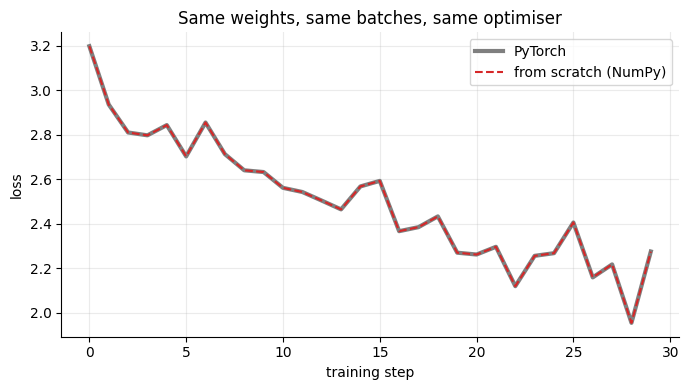

Largest loss difference over 30 steps: 6.59e-04  -> PASS


In [50]:
net_a = build_cnn(K, seed=SEED)
tw, _, _ = torch_twin(net_a, IMG, 8, 16, 64, K, dtype=torch.float32)
opt_a = Adam(net_a, lr=1e-3)
opt_t = torch.optim.Adam(tw.parameters(), lr=1e-3)

order = np.random.default_rng(SEED).permutation(len(X["train"]))
STEPS = 30
loss_a, loss_t = [], []
for s in range(STEPS):
    b = order[(s * BATCH_SIZE) % len(order):][:BATCH_SIZE]
    if len(b) < 2:
        b = order[:BATCH_SIZE]
    xb, yb = X["train"][b], Y["train"][b]
    l, d, _ = softmax_cross_entropy(net_a.forward(xb), yb)
    net_a.backward(d); opt_a.step(); loss_a.append(l)
    opt_t.zero_grad()
    lt = F.cross_entropy(tw(torch.from_numpy(xb)), torch.from_numpy(yb))
    lt.backward(); opt_t.step(); loss_t.append(lt.item())

TRAJ_DIFF = float(np.abs(np.array(loss_a) - np.array(loss_t)).max())
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(loss_t, label="PyTorch", lw=3, color="tab:gray"); ax.plot(loss_a, "--", label="from scratch (NumPy)", color="tab:red")
ax.set_xlabel("training step"); ax.set_ylabel("loss"); ax.set_title("Same weights, same batches, same optimiser"); ax.legend()
save_show("trajectory_check")
print(f"Largest loss difference over {STEPS} steps: {TRAJ_DIFF:.2e}  ->", "PASS" if TRAJ_DIFF < 1e-3 else "FAIL")

## Section 9 - Training

Training follows the usual loop: for every mini-batch, run the forward pass, compute the loss and its gradient, run the backward pass, and take an Adam step. Random horizontal flips are used as data augmentation (a flipped leaf is still a leaf). After every epoch the network is evaluated on the validation images with the macro-F1 score; the weights with the best validation macro-F1 are kept and training stops early if there is no improvement for `PATIENCE` epochs. Only 10 epochs are needed for this small network.

Configured training epochs: 10 (QUICK_TEST=False)
Epoch 01/10 | train loss 2.2608 | val loss 1.7070 acc 0.4693 macro-F1 0.4269
Epoch 02/10 | train loss 1.4032 | val loss 1.2246 acc 0.6248 macro-F1 0.5534
Epoch 03/10 | train loss 1.0991 | val loss 1.2330 acc 0.6014 macro-F1 0.5640
Epoch 04/10 | train loss 0.9372 | val loss 0.9843 acc 0.6861 macro-F1 0.6497
Epoch 05/10 | train loss 0.8192 | val loss 0.9708 acc 0.7053 macro-F1 0.6559
Epoch 06/10 | train loss 0.7382 | val loss 0.9314 acc 0.7078 macro-F1 0.6721
Epoch 07/10 | train loss 0.6739 | val loss 0.9047 acc 0.7257 macro-F1 0.6784
Epoch 08/10 | train loss 0.6165 | val loss 0.8167 acc 0.7547 macro-F1 0.7165
Epoch 09/10 | train loss 0.5648 | val loss 0.8622 acc 0.7372 macro-F1 0.6860
Epoch 10/10 | train loss 0.5037 | val loss 0.8311 acc 0.7372 macro-F1 0.7053

Best validation macro-F1 0.7165 | training time 44s


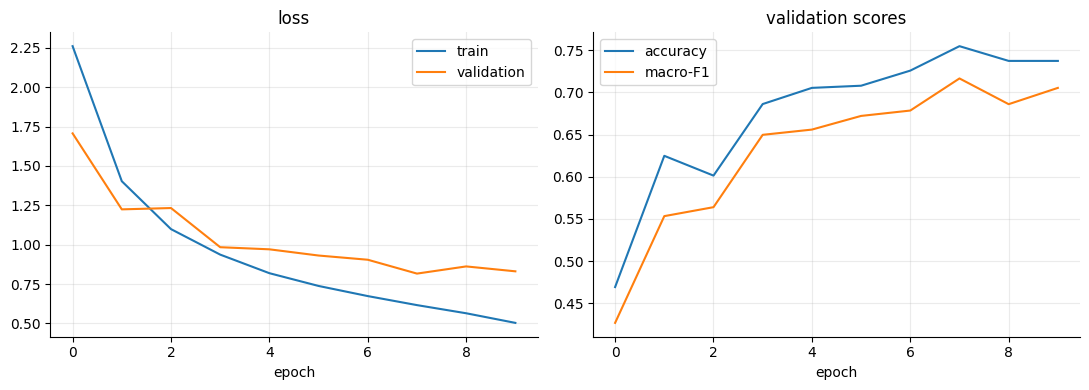

In [51]:
def predict(model, Xs, bs=256):
    out = []
    for i in range(0, len(Xs), bs):
        out.append(model.forward(Xs[i:i + bs], train=False))
    return np.concatenate(out)

net = build_cnn(K, seed=SEED)
opt = Adam(net, lr=LEARNING_RATE)
rng = np.random.default_rng(SEED)
hist = {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": []}
best_f1, best_w, bad, t0 = -1.0, None, 0, time.time()

print(f"Configured training epochs: {EPOCHS} (QUICK_TEST={QUICK_TEST})")
for ep in range(1, EPOCHS + 1):
    perm = rng.permutation(len(X["train"]))
    losses = []
    for i in range(0, len(perm), BATCH_SIZE):
        b = perm[i:i + BATCH_SIZE]
        xb, yb = X["train"][b], Y["train"][b]
        flip = rng.random(len(b)) < 0.5
        xb = np.where(flip[:, None, None, None], xb[:, :, :, ::-1], xb)       # random horizontal flip
        loss, dlog, _ = softmax_cross_entropy(net.forward(xb), yb)
        net.backward(dlog)
        opt.step()
        losses.append(loss)
    logits = predict(net, X["val"])
    vloss = softmax_cross_entropy(logits, Y["val"])[0]
    pred = logits.argmax(1)
    f1 = f1_score(Y["val"], pred, average="macro", zero_division=0)
    for k, v in zip(hist, [float(np.mean(losses)), vloss, float((pred == Y["val"]).mean()), f1]):
        hist[k].append(v)
    print(f"Epoch {ep:02d}/{EPOCHS} | train loss {hist['train_loss'][-1]:.4f} | val loss {vloss:.4f} acc {hist['val_acc'][-1]:.4f} macro-F1 {f1:.4f}")
    if f1 > best_f1:
        best_f1, best_w, bad = f1, net.get_weights(), 0
    else:
        bad += 1
        if bad >= PATIENCE:
            print("Early stopping"); break

train_time = time.time() - t0
net.set_weights(best_w)
print(f"\nBest validation macro-F1 {best_f1:.4f} | training time {train_time:.0f}s")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="validation")
ax[0].set_xlabel("epoch"); ax[0].set_title("loss"); ax[0].legend()
ax[1].plot(hist["val_acc"], label="accuracy"); ax[1].plot(hist["val_f1"], label="macro-F1")
ax[1].set_xlabel("epoch"); ax[1].set_title("validation scores"); ax[1].legend()
save_show("scratch_learning_curves")

## Section 10 - Evaluation on the Test Set

The best network is evaluated once on the test images, using the same metrics as the other models (accuracy and macro-averaged precision, recall and F1). The predictions are saved in `results/predictions/` in the same format as the other models, so that the results notebook can compare the from-scratch network with them, and the weights are saved in `models/`. The confusion matrix is row-normalised: each row shows how the images of one true class are distributed over the predicted classes.

Test accuracy 0.7569 | macro precision 0.6907 | macro recall 0.7601 | macro F1 0.7101 | 0.46 ms per image


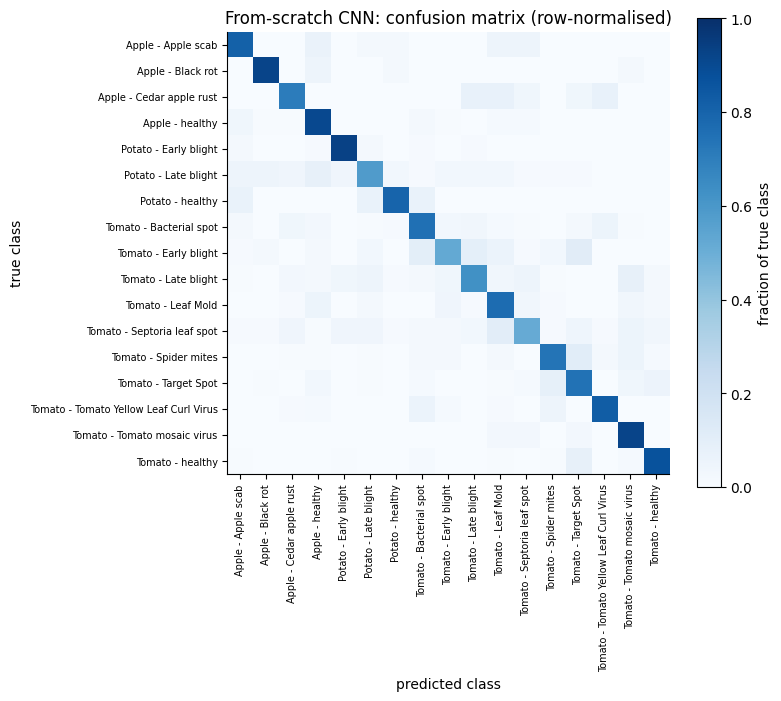

In [52]:
t0 = time.time()
logits = predict(net, X["test"])
infer_ms = (time.time() - t0) / len(X["test"]) * 1000
pred = logits.argmax(1)
acc = accuracy_score(Y["test"], pred)
P, R, F1, _ = precision_recall_fscore_support(Y["test"], pred, average="macro", zero_division=0)
print(f"Test accuracy {acc:.4f} | macro precision {P:.4f} | macro recall {R:.4f} | macro F1 {F1:.4f} | {infer_ms:.2f} ms per image")

pd.DataFrame({"path": frames["test"]["path"].map(lambda p: str(Path(p).relative_to(ROOT_DIR))), "y_true": Y["test"], "y_pred": pred}
             ).to_csv(PRED_DIR / "numpy_cnn_from_scratch_test_predictions.csv", index=False)
json.dump({"model": "NumPy CNN from scratch", "accuracy": acc, "macro_precision": P, "macro_recall": R, "macro_f1": F1,
           "parameters": int(net.n_params()), "train_time_s": train_time, "infer_ms_per_image": infer_ms, "image_size": IMG},
          open(PRED_DIR / "numpy_cnn_from_scratch_metrics.json", "w"), indent=1)
np.savez(MODELS / "numpy_cnn_from_scratch.npz", *net.get_weights())

cm = confusion_matrix(Y["test"], pred, labels=list(range(K)))
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_xticklabels(class_names, rotation=90, fontsize=7)
ax.set_yticks(range(K)); ax.set_yticklabels(class_names, fontsize=7)
ax.grid(False); ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
ax.set_title("From-scratch CNN: confusion matrix (row-normalised)")
fig.colorbar(im, ax=ax, label="fraction of true class")
save_show("scratch_confusion_matrix")

*Reading the result.* The score reflects a small network on $32\times32$ images and a subset of the training data, so it is expected to be lower than the PyTorch models on $224$ to $256$ pixel images. The point of this notebook is not the score but that the algorithm written from scratch behaves exactly like the library implementation (Section 7) and learns the task.

## Section 11 - Computational and Memory Complexity

**Notation.** $N$ images per batch, input $C_{in}\times H\times W$, $k\times k$ filters, $C_{out}$ output channels, output size $H_{out}\times W_{out}$.

**Time (multiply-accumulate operations, MACs).**

$$
\text{Conv: } \ N\,C_{out}\,H_{out}W_{out}\,C_{in}k^{2}, \qquad
\text{Dense: } \ N\,n_{in}\,n_{out},\qquad
\text{Pool, ReLU: } \ O(N\,C\,H\,W).
$$

The backward pass of a layer needs two products of the same size as the forward product (one for the weight gradient, one for the input gradient), so one training step costs about **3 times the forward pass**. One epoch over $M$ images therefore costs about $3\,M\,\times$(forward cost per image) and is linear in the number of images. For a fixed number of layers, the time grows **linearly with the batch size $N$**, **quadratically with the image side** $H$ (the number of positions), and **linearly with the number of filters** of a layer whose input width is fixed, or **quadratically** when both input and output channels grow together.

**Memory.** Weights: $C_{out}C_{in}k^2$ per conv layer and $n_{in}n_{out}$ per dense layer. Training must also *keep* the activations of every layer for the backward pass, $N\,C_{out}H_{out}W_{out}$ per layer, so memory grows linearly with $N$ and quadratically with $H$. This implementation stores, in addition, the **im2col matrix** of every convolution, which holds $k^2$ copies of the input: this trades memory ($\times k^2$ per conv layer) for speed, because one large matrix product is much faster than loops.

The next cell measures the time and the peak memory of one forward + backward pass while varying one quantity at a time (batch size, image size, number of filters), and fits the slope on a log-log scale, which estimates the exponent $a$ in cost $\propto x^{a}$. Memory is measured with `tracemalloc`, which tracks NumPy allocations.

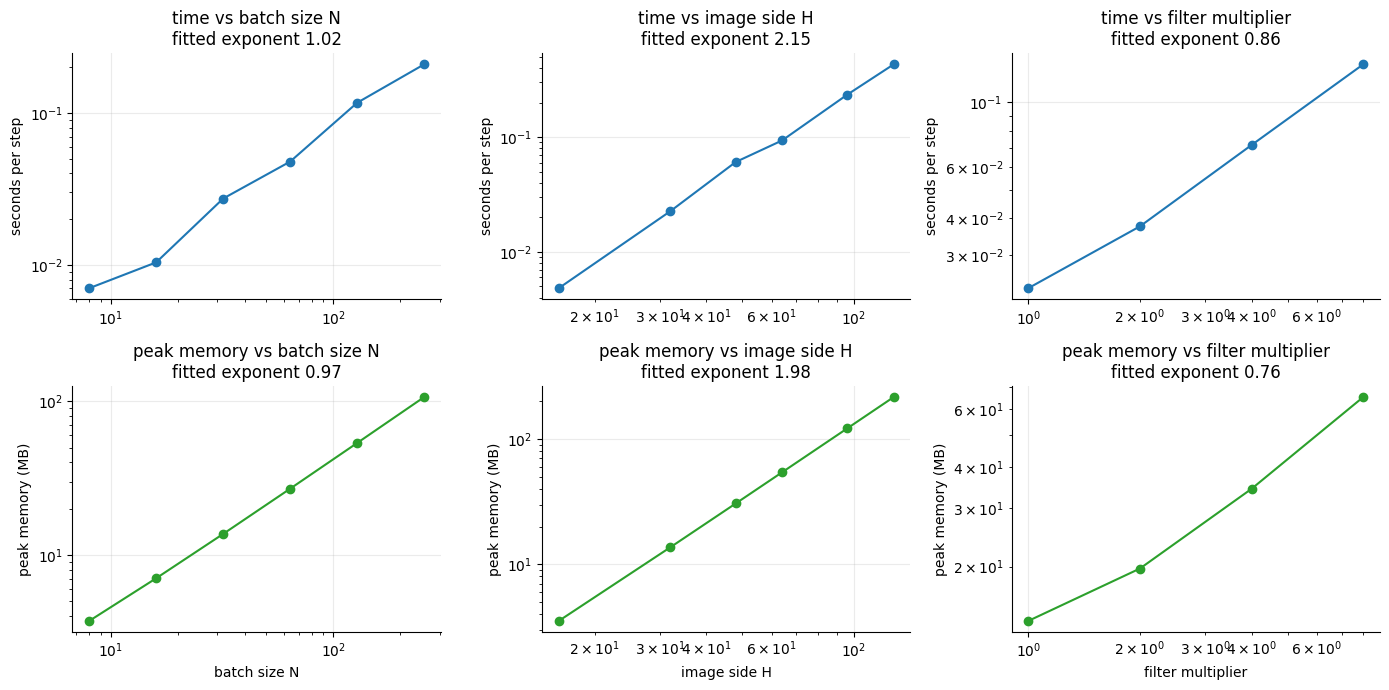

,varied quantity,theoretical exponent (time),measured exponent (time),measured exponent (memory)
0,batch size N,1.0,1.02,0.97
1,image side H,2.0,2.15,1.98
2,filter multiplier,1 to 2,0.86,0.76


In [53]:
def measure(N=32, hw=32, mult=1, reps=3):
    model = build_cnn(K, hw=hw, c1=8 * mult, c2=16 * mult, hidden=64, seed=0)
    x = np.random.default_rng(0).standard_normal((N, 3, hw, hw)).astype(np.float32)
    y_ = np.zeros(N, dtype=int)
    def step():
        _, d, _ = softmax_cross_entropy(model.forward(x), y_)
        model.backward(d)
    step()                                                  # warm-up
    times = []
    for _ in range(reps):
        t0 = time.perf_counter(); step(); times.append(time.perf_counter() - t0)
    tracemalloc.start(); step(); _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    return min(times), peak / 1e6

sweeps = {
    "batch size N":     ([8, 16, 32, 64, 128, 256],       lambda v: dict(N=v)),
    "image side H":     ([16, 32, 48, 64, 96, 128],       lambda v: dict(hw=v)),
    "filter multiplier": ([1, 2, 4, 8],                   lambda v: dict(mult=v)),
}
scal = {}
for name, (vals, mk) in sweeps.items():
    scal[name] = [(v, *measure(**mk(v))) for v in vals]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
summary = []
for j, (name, data) in enumerate(scal.items()):
    v = np.array([d[0] for d in data], float); t_ = np.array([d[1] for d in data]); m_ = np.array([d[2] for d in data])
    a_t, b_t = np.polyfit(np.log(v), np.log(t_), 1); a_m, b_m = np.polyfit(np.log(v), np.log(m_), 1)
    summary.append((name, a_t, a_m))
    axes[0, j].loglog(v, t_, "o-"); axes[0, j].set_title(f"time vs {name}\nfitted exponent {a_t:.2f}")
    axes[1, j].loglog(v, m_, "o-", color="tab:green"); axes[1, j].set_title(f"peak memory vs {name}\nfitted exponent {a_m:.2f}")
    axes[0, j].set_ylabel("seconds per step"); axes[1, j].set_ylabel("peak memory (MB)")
    axes[1, j].set_xlabel(name)
save_show("complexity_scaling")

theory = {"batch size N": 1.0, "image side H": 2.0, "filter multiplier": "1 to 2"}
display(pd.DataFrame([(n, theory[n], round(a, 2), round(b, 2)) for n, a, b in summary],
                     columns=["varied quantity", "theoretical exponent (time)", "measured exponent (time)", "measured exponent (memory)"]))

*Reading the plots.* Slopes close to the theoretical exponents confirm the analysis. Small deviations are expected: for very small inputs the fixed Python overhead dominates the time (slope below the theory), and for large inputs memory-bandwidth and cache effects appear. For the filter sweep the theoretical exponent lies between 1 and 2 because the second convolution grows with $C_{in}C_{out}$ (quadratically) while the dense layer and the first convolution grow only linearly; at these small sizes the measured value stays near the lower end. The memory exponent for the filter sweep is also below 1 at first, because the im2col matrix of the first convolution depends only on the input image and dominates until the number of filters is large.

The next cell compares the cost of the from-scratch implementation with PyTorch on the same architecture and batch, and then counts the parameters and multiply-accumulate operations of the networks used in the project. MACs are counted with forward hooks (convolution and linear layers); the activation memory is the number of values produced by the layers of one forward pass, stored as 4-byte floats. The PyTorch networks are created without pretrained weights, since only their structure matters here.

In [54]:
# --- speed of the NumPy implementation against PyTorch (same architecture, batch of 64 images of 32x32)
xb = X["train"][:64]; yb = Y["train"][:64]
ours_net = build_cnn(K, seed=0)
tw32, _, _ = torch_twin(ours_net, IMG, 8, 16, 64, K, dtype=torch.float32)
xt, yt = torch.from_numpy(xb), torch.from_numpy(yb)

def ours_step():
    _, d, _ = softmax_cross_entropy(ours_net.forward(xb), yb); ours_net.backward(d)
def torch_step():
    tw32.zero_grad(); F.cross_entropy(tw32(xt), yt).backward()

def best_time(fn, reps=5):
    fn(); return min((lambda t0: (fn(), time.perf_counter() - t0)[1])(time.perf_counter()) for _ in range(reps))
t_ours, t_torch = best_time(ours_step), best_time(torch_step)
print(f"One training step (forward + backward), batch 64: NumPy {t_ours * 1000:.1f} ms | PyTorch {t_torch * 1000:.1f} ms "
      f"-> NumPy is {t_ours / t_torch:.1f}x slower")

# --- parameters, MACs and activation memory of the models used in the project
def count_torch(model, shape):
    macs, acts = [0], [0]
    def hook(m, i, o):
        if isinstance(m, nn.Conv2d):
            macs[0] += o.shape[2] * o.shape[3] * m.out_channels * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
        elif isinstance(m, nn.Linear):
            macs[0] += m.in_features * m.out_features
        acts[0] += o.numel()
    hs = [m.register_forward_hook(hook) for m in model.modules() if not list(m.children())]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *shape))
    for h in hs: h.remove()
    return sum(p.numel() for p in model.parameters()), macs[0], acts[0] * 4 / 1e6

def conv_block(a, b):
    return nn.Sequential(nn.Conv2d(a, b, 3, padding=1, bias=False), nn.BatchNorm2d(b), nn.ReLU(), nn.MaxPool2d(2))
project_cnn = nn.Sequential(conv_block(3, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 256),
                            nn.AdaptiveAvgPool2d(4), nn.Flatten(), nn.Linear(4096, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, K))
from torchvision.models import resnet18
r18 = resnet18(weights=None); r18.fc = nn.Linear(512, K)
scratch_t, _, _ = torch_twin(ours_net, IMG, 8, 16, 64, K, dtype=torch.float32)

rows = []
for name, m, shape in [("NumPy CNN from scratch (32x32)", scratch_t, (3, 32, 32)),
                       ("Custom CNN, PyTorch (256x256)", project_cnn, (3, 256, 256)),
                       ("ResNet18 (224x224)", r18, (3, 224, 224))]:
    p, macs, mb = count_torch(m, shape)
    rows.append((name, f"{p:,}", f"{p * 4 / 1e6:.1f}", f"{macs / 1e6:,.1f}", f"{mb:.1f}"))
cost = pd.DataFrame(rows, columns=["model", "parameters", "weights (MB)", "forward cost (million MACs / image)", "activations (MB / image)"])
cost.to_csv(RESULTS / "model_cost.csv", index=False)
display(cost)

One training step (forward + backward), batch 64: NumPy 55.7 ms | PyTorch 33.1 ms -> NumPy is 1.7x slower


,model,parameters,weights (MB),forward cost (million MACs / image),activations (MB / image)
0,NumPy CNN from scratch (32x32),"68,097",0.3,0.6,0.1
1,"Custom CNN, PyTorch (256x256)","1,442,097",5.8,963.6,51.2
2,ResNet18 (224x224),"11,185,233",44.7,"1,813.6",29.9


**Complexity of the other methods in the project.** With $n$ training images, $p$ features per image, $B$ trees and $n_{SV}$ support vectors:

| Method | Training time | Prediction time (one image) | Memory | Comment |
|---|---|---|---|---|
| CNN (PyTorch and NumPy) | $O(\text{epochs}\cdot n\cdot\text{MACs per image})$ | one forward pass, $O(\text{MACs})$ | weights + activations (+ im2col in NumPy) | cost independent of $n$ at prediction time |
| ResNet18 fine-tuning | same, with a larger network | $\approx 1.8$ billion MACs | 11.2 million weights | pretraining removes most of the epochs |
| SVM with RBF kernel | between $O(n^{2}p)$ and $O(n^{3})$ | $O(n_{SV}\,p)$ | the $n_{SV}$ support vectors | slow for large $n$; PCA reduces $p$ |
| Random forest | $O(B\cdot p'\,n\log n)$ with $p'\approx\sqrt{p}$ candidate features per split | $O(B\cdot\text{depth})$ | $O(\text{number of nodes})$ | trains in parallel; prediction is very cheap |
| Logistic regression | $O(\text{iterations}\cdot n\cdot p\cdot K)$ | $O(pK)$ | $O(pK)$ | used for the fusion experiment |
| Image-text alignment | $O(\text{epochs}\cdot n\cdot(512\,d))$ with $d$ the text vocabulary size | $O(512\,d+Kd)$ | $512\,d$ weights | tiny; needs the image features |
| Feature extraction | HOG $O(H\,W)$ per image; ResNet18 forward pass | - | feature matrices: $n\,p$ floats | the cached arrays are 170 MB (hand-crafted) and 48 MB (deep) for 23,000 images |

The one-off costs (feature extraction, SVM training) are what make the classical methods slower to *prepare*, while their prediction cost is small; the CNNs are the opposite, expensive to train but quick to use.

## Section 12 - Limitations and Possible Bugs

**Automated tests.** The cell below runs twelve checks of the from-scratch code, including edge cases where bugs typically hide: batch size 1, odd image sizes, invalid labels, determinism, numerical stability with extreme logits, and the ability to overfit a tiny batch (a network that cannot even memorise 16 images has a bug). It prints a pass/fail table.

In [55]:
tests = []
def check(name, fn):
    try:
        ok, detail = fn()
    except Exception as e:
        ok, detail = False, f"{type(e).__name__}: {e}"
    tests.append((name, "PASS" if ok else "FAIL", detail))

def t_shape():
    out = build_cnn(K).forward(X["train"][:5]); return out.shape == (5, K), str(out.shape)
def t_probs():
    p = softmax_cross_entropy(build_cnn(K).forward(X["train"][:7]), Y["train"][:7])[2]; return np.allclose(p.sum(1), 1), "rows sum to 1"
def t_gradcheck():
    return GRAD_CHECK_ERR < 1e-6, f"max relative error {GRAD_CHECK_ERR:.1e}"
def t_torch():
    return TORCH_DIFF < 1e-9, f"max difference {TORCH_DIFF:.1e}"
def t_traj():
    return TRAJ_DIFF < 1e-3, f"max loss difference {TRAJ_DIFF:.1e}"
def t_batch1():
    m = build_cnn(K); out = m.forward(X["train"][:1]); l, d, _ = softmax_cross_entropy(out, Y["train"][:1]); m.backward(d); return np.isfinite(l), "batch size 1 works"
def t_odd():
    try:
        build_cnn(K).forward(np.zeros((1, 3, 30, 30), np.float32)); return False, "no error raised for 30x30 input"
    except ValueError as e:
        return True, "odd feature-map size is rejected with ValueError"
def t_labels():
    try:
        softmax_cross_entropy(np.zeros((2, 3)), np.array([0, 5])); return False, "invalid label accepted"
    except IndexError:
        return True, "label outside the class range raises IndexError"
def t_stable():
    l = softmax_cross_entropy(np.array([[1e4, 0.0, -1e4]]), np.array([0]))[0]; return np.isfinite(l) and l < 1e-6, f"loss {l:.1e} with logits of size 1e4"
def t_overfit():
    m, o = build_cnn(K, seed=3), None
    o = Adam(m, lr=3e-3); xb, yb = X["train"][:16], Y["train"][:16]
    for _ in range(150):
        l, d, _ = softmax_cross_entropy(m.forward(xb), yb); m.backward(d); o.step()
    return l < 0.1, f"loss on 16 images after 150 steps: {l:.3f}"
def t_determinism():
    r = []
    for _ in range(2):
        m = build_cnn(K, seed=5); l, d, _ = softmax_cross_entropy(m.forward(X["train"][:8]), Y["train"][:8]); r.append(l)
    return r[0] == r[1], "same seed gives identical loss"
def t_nan():
    return all(np.isfinite(w).all() for w in net.get_weights()), "no NaN or infinite weights after training"

for n, f in [("output shape (N, K)", t_shape), ("softmax probabilities sum to 1", t_probs), ("numerical gradient check", t_gradcheck),
             ("agreement with PyTorch (float64)", t_torch), ("same training trajectory as PyTorch", t_traj), ("batch of one image", t_batch1),
             ("odd image size rejected", t_odd), ("invalid label rejected", t_labels), ("stable with extreme logits", t_stable),
             ("overfits a tiny batch", t_overfit), ("determinism with a fixed seed", t_determinism), ("trained weights are finite", t_nan)]:
    check(n, f)
result = pd.DataFrame(tests, columns=["test", "result", "detail"])
display(result)
print(f"{(result['result'] == 'PASS').sum()} of {len(result)} tests passed")
result.to_csv(RESULTS / "implementation_tests.csv", index=False)

,test,result,detail
0,"output shape (N, K)",PASS,"(5, 17)"
1,softmax probabilities sum to 1,PASS,rows sum to 1
2,numerical gradient check,PASS,max relative error 4.7e-10
3,agreement with PyTorch (float64),PASS,max difference 6.7e-16
4,same training trajectory as PyTorch,PASS,max loss difference 6.6e-04
5,batch of one image,PASS,batch size 1 works
6,odd image size rejected,PASS,odd feature-map size is rejected with ValueError
7,invalid label rejected,PASS,label outside the class range raises IndexError
8,stable with extreme logits,PASS,loss 0.0e+00 with logits of size 1e4
9,overfits a tiny batch,PASS,loss on 16 images after 150 steps: 0.000


12 of 12 tests passed


**Limitations of the from-scratch implementation.**

* **Speed.** It runs on one CPU core (plus NumPy's BLAS threads) and is slower than PyTorch by the factor measured in Section 11; there is no GPU support, so training at $224\times224$ would be impractical, which is why the images are reduced to $32\times32$ and a small network is used.
* **Memory.** The im2col matrix multiplies the memory of every convolution by $k^2=9$; large images or batches can exhaust memory (see the memory curves).
* **Limited feature set.** Only $3\times3$ convolutions with stride 1 and zero padding, $2\times2$ max-pooling with even feature-map sizes, no batch normalisation, dropout, learning-rate schedule, weight decay or mixed precision. The image side must be divisible by 4.
* **Numerical precision.** Single precision (float32) is used for training, so results can differ from PyTorch in the last digits and, over many steps, drift slightly; the checks above were done in double precision for exactness.
* **Ties in max-pooling.** When several values in a window are equal the gradient goes to the first one, as in PyTorch; a numerical gradient check can be unreliable exactly at such ties or at the ReLU kink at 0 (the random test data avoids them).
* **Accuracy.** A small network on $32\times32$ images cannot match the $256\times256$ PyTorch model, so its score is only a correctness demonstration.

**Possible bugs and limitations in the rest of the project code.**

* **Stale feature cache.** The benchmark notebook caches features in `data/features/` and reuses a file when the number of rows matches; if the preprocessing is changed (for example the HOG settings), the old file is silently reused. *Remedy: delete `data/features/` after changing preprocessing.*
* **Possible leakage between splits.** PlantVillage contains several photographs of the same leaf, and the stratified random split does not keep them together, which can inflate all test scores. *Remedy: group by leaf using the repository's leaf map.*
* **Dataset bias.** Uniform backgrounds let models use capture conditions as shortcuts, so no score here predicts field performance.
* **Path handling.** The notebooks find the repository root from the working folder (`notebooks/` or the root); running Jupyter from any other folder breaks the relative paths. *Remedy: start Jupyter from the repository root.*
* **Platform differences.** `num_workers = 0` is used for portability, which is slower; GPU (CUDA or Apple MPS) results can differ slightly from CPU results and are not bit-for-bit reproducible.
* **Single split, single seed.** Differences of a few tenths of a percent are within noise; the results notebook tests significance.
* **Text modality.** The symptom descriptions apply to whole classes, so they cannot be used as per-image inputs without leaking the label (the notebooks use them only as class descriptions), and the TF-IDF encoder knows only word counts.
* **Network access.** The first run needs internet for the data download (git) and for the pretrained ResNet18 weights.

## Section 13 - Summary

In [56]:
summary = pd.DataFrame({
    "item": ["algorithm implemented from scratch", "lines of model code (layers, loss, optimiser)", "parameters", "numerical gradient check",
             "agreement with PyTorch (float64)", "same training trajectory as PyTorch (30 steps)", "automated tests passed",
             "test accuracy (32x32 images)", "test macro-F1", "training time"],
    "value": ["convolutional neural network (NumPy only)", "about 135", f"{net.n_params():,}", f"max relative error {GRAD_CHECK_ERR:.1e}",
              f"max difference {TORCH_DIFF:.1e}", f"max loss difference {TRAJ_DIFF:.1e}", f"{(result['result'] == 'PASS').sum()} of {len(result)}",
              f"{acc:.4f}", f"{F1:.4f}", f"{train_time:.0f} s"],
})
summary.to_csv(RESULTS / "implementation_summary.csv", index=False)
display(summary)
print("Saved to:", RESULTS)

,item,value
0,algorithm implemented from scratch,convolutional neural network (NumPy only)
1,"lines of model code (layers, loss, optimiser)",about 135
2,parameters,"68,097"
3,numerical gradient check,max relative error 4.7e-10
4,agreement with PyTorch (float64),max difference 6.7e-16
5,same training trajectory as PyTorch (30 steps),max loss difference 6.6e-04
6,automated tests passed,12 of 12
7,test accuracy (32x32 images),0.7569
8,test macro-F1,0.7101
9,training time,44 s


Saved to: /Users/sabyasachi/plant_disease_based_classification/results/implementation


**Outputs written by this notebook:** `models/numpy_cnn_from_scratch.npz` (weights), `results/predictions/numpy_cnn_from_scratch_*` (test predictions and metrics for the comparison notebook), and the figures and tables in `results/implementation/`.

## References

Chellapilla, K., Puri, S. & Simard, P. 2006, High performance convolutional neural networks for document processing, *Tenth International Workshop on Frontiers in Handwriting Recognition*.

He, K., Zhang, X., Ren, S. & Sun, J. 2015, Delving deep into rectifiers: surpassing human-level performance on ImageNet classification, *Proceedings of the IEEE International Conference on Computer Vision*, pp. 1026-1034.

Kingma, D. P. & Ba, J. 2015, Adam: a method for stochastic optimization, *International Conference on Learning Representations*, arXiv:1412.6980.

LeCun, Y., Bottou, L., Bengio, Y. & Haffner, P. 1998, Gradient-based learning applied to document recognition, *Proceedings of the IEEE*, vol. 86, no. 11, pp. 2278-2324.

Paszke, A., Gross, S., Massa, F. et al. 2019, PyTorch: an imperative style, high-performance deep learning library, *Advances in Neural Information Processing Systems*, vol. 32.

Rumelhart, D. E., Hinton, G. E. & Williams, R. J. 1986, Learning representations by back-propagating errors, *Nature*, vol. 323, pp. 533-536.